In [1]:
import pandas as pd

df = pd.read_csv('insurance.csv')

df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [2]:
df.age.mean()

np.float64(39.20702541106129)

In [3]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [4]:
df.sex.value_counts()

sex
male      676
female    662
Name: count, dtype: int64

In [5]:
df.sex.value_counts(normalize = True)

sex
male      0.505232
female    0.494768
Name: proportion, dtype: float64

In [6]:
categorical_counts = df.select_dtypes(include = ['object']).apply(pd.Series.value_counts)

In [7]:
categorical_counts

,sex,smoker,region
female,662.0,NaN,NaN
male,676.0,NaN,NaN
no,NaN,1064.0,NaN
northeast,NaN,NaN,324.0
northwest,NaN,NaN,325.0
southeast,NaN,NaN,364.0
southwest,NaN,NaN,325.0
yes,NaN,274.0,NaN


In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np 

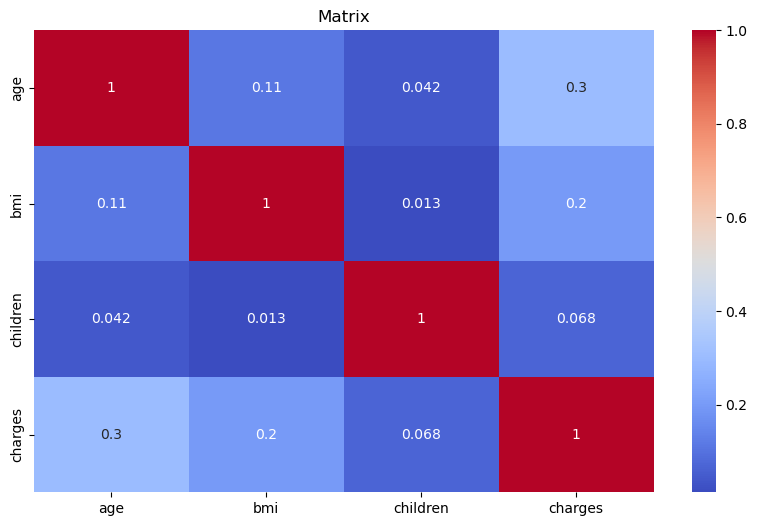

In [9]:
plt.figure(figsize = (10,6))

numeric_data= df.select_dtypes(include = [np.number])
correlation_matrix = numeric_data.corr()
sns.heatmap(correlation_matrix, annot = True, cmap = "coolwarm" ) 
plt.title("Matrix")
plt.show()

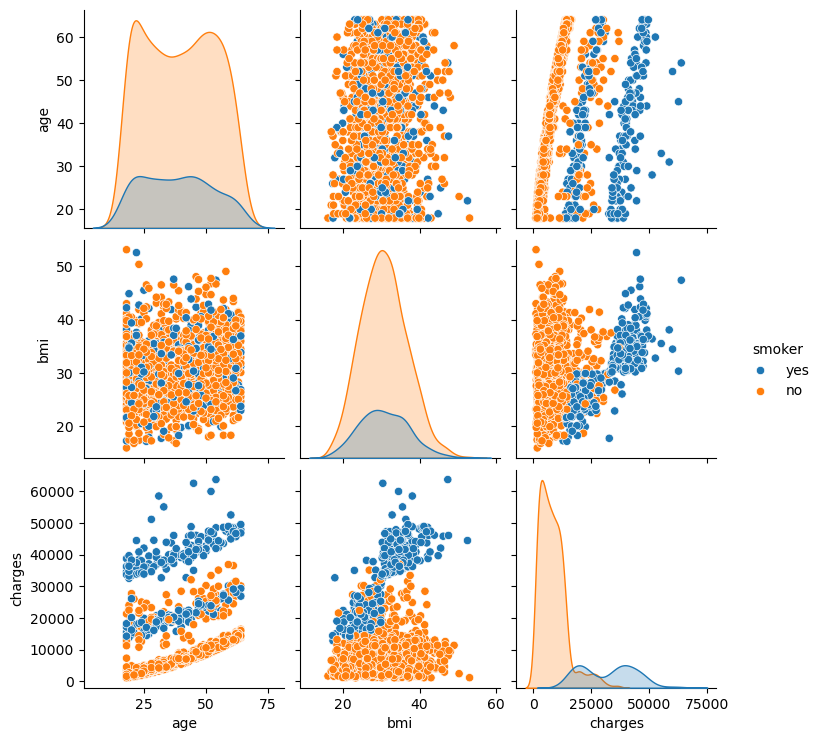

In [10]:
sns.pairplot(df, vars = ['age', 'bmi', 'charges'], hue = 'smoker')
plt.show()

In [11]:
avg_charges_smokers = df.groupby('smoker')['charges'].mean()

print(avg_charges_smokers)

avg_charges_region = df.groupby('region')['charges'].mean()
print(avg_charges_region)

smoker
no      8434.268298
yes    32050.231832
Name: charges, dtype: float64
region
northeast    13406.384516
northwest    12417.575374
southeast    14735.411438
southwest    12346.937377
Name: charges, dtype: float64
